# Breast Cancer Machine Learning Project  

The Breast Cancer Wisconsin (Diagnostic) dataset contains 569 patients. 
There are 30 features ranging from radius to symmetry. 

### Problem Significance

Breast cancer diagnosis is important since identifying malignant tumors can support timely follow-up and treatment. A false negative is especially concerning because it means a malignant tumor was incorrectly classified as benign. This project examines how machine learning can help distinguish between malignant and benign cases, although it is not intended to replace clinical diagnosis.

### Problem Type and Evaluation Metrics

This is a supervised binary classification problem because every sample has a known diagnosis and the model predicts one of two categories: malignant or benign.

Macro F1 is the primary metric because it combines precision and recall while giving malignant and benign cases equal importance. Malignant recall is also evaluated because it measures the percentage of malignant cases correctly identified. Low malignant recall would indicate that more malignant tumors were incorrectly classified as benign.

In [1]:
#import data from UCI ML Data Repository 
# URL: https://archive.ics.uci.edu/dataset/17/breast+cancer+wisconsin+diagnostic 

import pandas as pd
import matplotlib.pyplot as plt

from sklearn.datasets import load_breast_cancer
cancer = load_breast_cancer(as_frame=True)

X = cancer.data.copy()
y = cancer.target.copy()

print("Feature shape:", X.shape)
print("Target shape:", y.shape)
print("Target names:", cancer.target_names)

Feature shape: (569, 30)
Target shape: (569,)
Target names: ['malignant' 'benign']


### Dataset

The Breast Cancer Wisconsin Diagnostic dataset comes from the UCI Machine Learning Repository.

- 569 patient records
- 30 numerical features
- Features describe cell nuclei measurements such as radius, texture, perimeter,
  area, smoothness, compactness, concavity, symmetry, and fractal dimension
- Target classes: malignant and benign

In [2]:
# show the first rows
X.head()

,mean radius,mean texture,mean perimeter,mean area,mean smoothness,mean compactness,mean concavity,mean concave points,mean symmetry,mean fractal dimension,...,worst radius,worst texture,worst perimeter,worst area,worst smoothness,worst compactness,worst concavity,worst concave points,worst symmetry,worst fractal dimension
0,17.99,10.38,122.80,1001.0,0.11840,0.27760,0.3001,0.14710,0.2419,0.07871,...,25.38,17.33,184.60,2019.0,0.1622,0.6656,0.7119,0.2654,0.4601,0.11890
1,20.57,17.77,132.90,1326.0,0.08474,0.07864,0.0869,0.07017,0.1812,0.05667,...,24.99,23.41,158.80,1956.0,0.1238,0.1866,0.2416,0.1860,0.2750,0.08902
2,19.69,21.25,130.00,1203.0,0.10960,0.15990,0.1974,0.12790,0.2069,0.05999,...,23.57,25.53,152.50,1709.0,0.1444,0.4245,0.4504,0.2430,0.3613,0.08758
3,11.42,20.38,77.58,386.1,0.14250,0.28390,0.2414,0.10520,0.2597,0.09744,...,14.91,26.50,98.87,567.7,0.2098,0.8663,0.6869,0.2575,0.6638,0.17300
4,20.29,14.34,135.10,1297.0,0.10030,0.13280,0.1980,0.10430,0.1809,0.05883,...,22.54,16.67,152.20,1575.0,0.1374,0.2050,0.4000,0.1625,0.2364,0.07678


In [3]:
# inspect the data
X.info()
X.describe().T

# check for missing values and duplicates
print("Missing values in each column:\n", X.isnull().sum())
print("Number of duplicate rows:", X.duplicated().sum())

#The target values are 0 and 1, where 0 represents malignant and 1 represents benign. 
y.value_counts()

<class 'pandas.DataFrame'>
RangeIndex: 569 entries, 0 to 568
Data columns (total 30 columns):
 #   Column                   Non-Null Count  Dtype  
---  ------                   --------------  -----  
 0   mean radius              569 non-null    float64
 1   mean texture             569 non-null    float64
 2   mean perimeter           569 non-null    float64
 3   mean area                569 non-null    float64
 4   mean smoothness          569 non-null    float64
 5   mean compactness         569 non-null    float64
 6   mean concavity           569 non-null    float64
 7   mean concave points      569 non-null    float64
 8   mean symmetry            569 non-null    float64
 9   mean fractal dimension   569 non-null    float64
 10  radius error             569 non-null    float64
 11  texture error            569 non-null    float64
 12  perimeter error          569 non-null    float64
 13  area error               569 non-null    float64
 14  smoothness error         569 non-null

target
1    357
0    212
Name: count, dtype: int64

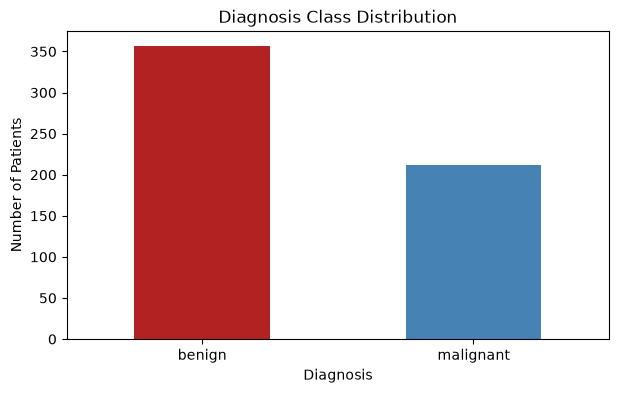

In [4]:
# plot the class distribution
target_counts = y.map({
    0: "malignant",
    1: "benign"
}).value_counts()

plt.figure(figsize=(7, 4))
target_counts.plot(
    kind="bar",
    color=["firebrick", "steelblue"],
    title="Diagnosis Class Distribution",
    ylabel="Number of Patients",
    xlabel="Diagnosis"
)

plt.ylim(bottom=0)
plt.xticks(rotation=0)
plt.show()

### Diagnosis Distribution Interpretation

The dataset contains 357 benign cases and 212 malignant cases, showing moderate class imbalance. Both diagnoses are sufficiently represented, but the larger number of benign cases means that regular accuracy should not be used by itself. This supports using a stratified split, macro F1, malignant recall, and class weight as a tuning parameter.

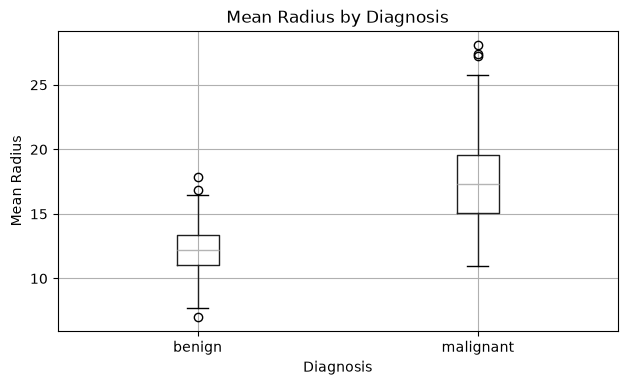

In [5]:
# label the target classes
diagnosis_labels = y.map({
    0: "malignant",
    1: "benign"
})

plot_data = X.copy()
plot_data["diagnosis"] = diagnosis_labels

# compare mean radius by diagnosis
plot_data.boxplot(
    column="mean radius",
    by="diagnosis",
    figsize=(7, 4)
)

plt.title("Mean Radius by Diagnosis")
plt.suptitle("")
plt.xlabel("Diagnosis")
plt.ylabel("Mean Radius")
plt.show()

### Mean Radius Interpretation

Malignant cases generally have larger mean-radius measurements than benign cases. However, the distributions overlap and both groups contain outliers. This suggests that mean radius provides useful information, but it cannot correctly classify every case by itself, so the models use all 30 features.

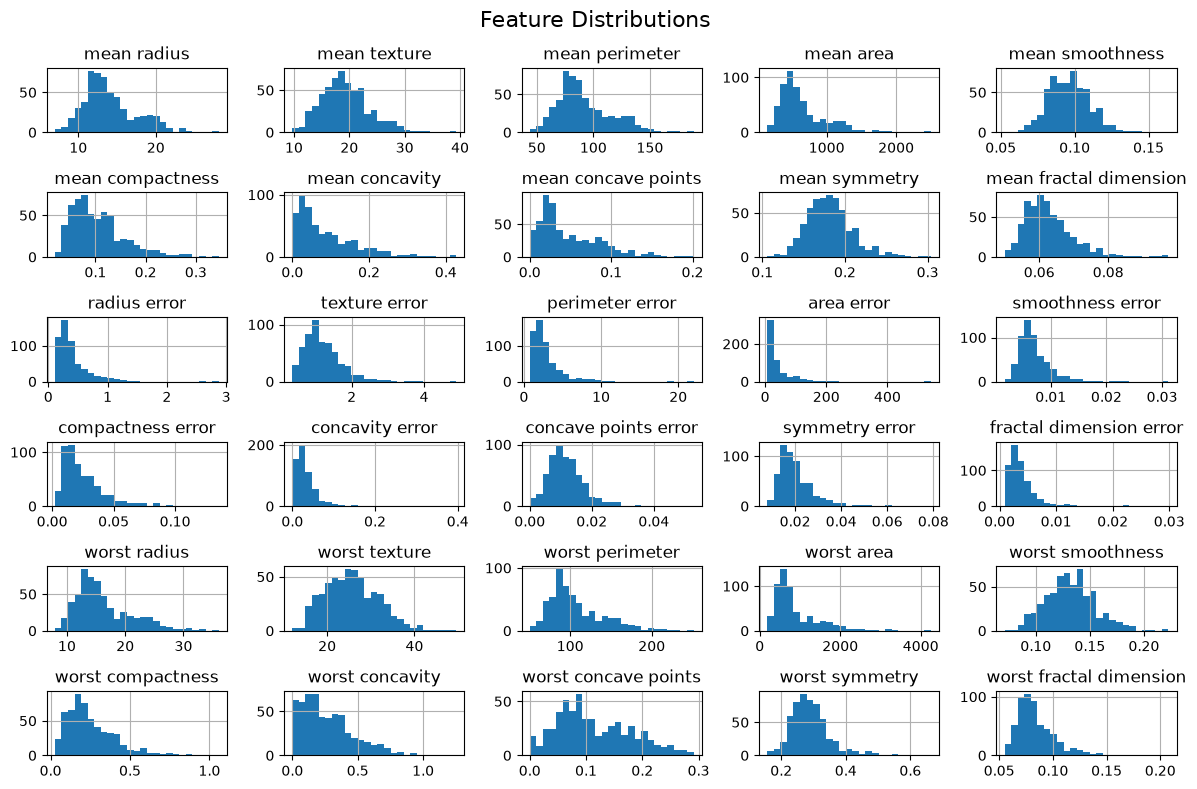

In [6]:
# plot feature distributions
X.hist(
    bins=25,
    figsize=(12, 8),
    layout=(6, 5)
)

plt.suptitle("Feature Distributions", fontsize=16)
plt.tight_layout()
plt.show()

### Feature Distribution Interpretation

The features have different distributions, numerical ranges, and levels of skewness. Measurements such as area are much larger numerically than features such as smoothness and fractal dimension. These differences support standardizing the features before fitting Logistic Regression.

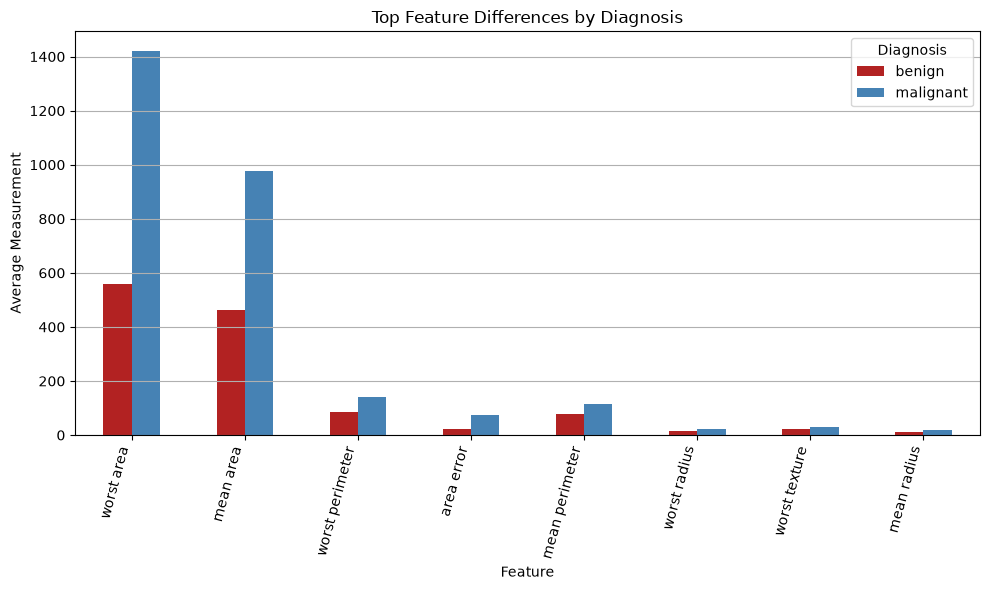

In [7]:
# compare the most different features by diagnosis
feature_means = plot_data.groupby("diagnosis")[X.columns].mean()
feature_difference = (
    feature_means.loc["malignant"] - feature_means.loc["benign"]
).abs().sort_values(ascending=False)
top_features = feature_difference.head(8).index

feature_means[top_features].T.plot(
    kind="bar",
    figsize=(10, 6),
    color=["firebrick", "steelblue"],
    title="Top Feature Differences by Diagnosis"
)

plt.xlabel("Feature")
plt.ylabel("Average Measurement")
plt.xticks(rotation=75, ha="right")
plt.legend(title="Diagnosis")
plt.grid(axis="y")
plt.tight_layout()
plt.show()

### Feature-Difference Interpretation

Area- and perimeter-related measurements show some of the largest raw differences between malignant and benign cases. However, the features use different units and scales, so the bar heights should not be interpreted as direct measures of feature importance. The graph instead shows that several measurements contain information that may help distinguish between the diagnoses.

In [8]:
from sklearn.model_selection import train_test_split

# split the data into training and testing sets
X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.2,
    random_state=42,
    stratify=y
)

print("Training features:", X_train.shape)
print("Testing features:", X_test.shape)

Training features: (455, 30)
Testing features: (114, 30)


### Preprocessing Decisions

The dataset contains no missing values or duplicate rows. All 30 predictors are numerical, so ordinal and one-hot encoding are unnecessary. A median imputer is retained in the pipeline as a safeguard against possible missing values.

StandardScaler places the numerical features on comparable scales. Scaling is important for Logistic Regression because features with larger numerical ranges could otherwise have too much influence. Random Forest does not require scaling, but scaling does not change its threshold-based decisions.

Preprocessing is performed inside each model pipeline so that the imputer and scaler are fitted only to the training portion of each cross-validation fold. This prevents information from the validation or test data from leaking into model training.

In [9]:
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import StandardScaler

# use all columns as numerical features
numeric_features = X.columns.tolist()

# fill missing values and standardize the features
numeric_pipeline = Pipeline([
    ("imputer", SimpleImputer(strategy="median")),
    ("scaler", StandardScaler())
])

# apply the preprocessing steps to the numerical columns
preprocessor = ColumnTransformer([
    ("numeric", numeric_pipeline, numeric_features)
])

## Validation Strategy

The data is split into 80% training data and 20% test data.

`GridSearchCV` uses five-fold cross-validation on the training data to select the best hyperparameters. Because this is a classification problem, scikit-learn uses stratified folds when `cv=5` is provided.

The test set is not used during tuning. It is reserved for the final evaluation.

### Why macro F1?

F1-score combines precision and recall into one score. Macro F1 calculates the F1-score for malignant and benign separately, then gives both classes equal importance by averaging them. This is useful because the class sizes are different and both types of prediction matter.

In [10]:
from sklearn.linear_model import LogisticRegression
from sklearn.ensemble import RandomForestClassifier
from sklearn.model_selection import GridSearchCV
from sklearn.metrics import (
    classification_report,
    ConfusionMatrixDisplay,
    f1_score,
    recall_score
)

# build the logistic regression pipeline
logistic_pipeline = Pipeline([
    ("preprocessor", preprocessor),
    ("model", LogisticRegression(
        solver="saga",
        max_iter=20000,
        tol=1e-3,
        random_state=42
    ))
])

# set the parameters to tune
logistic_parameters = {
    # l1_ratio 0 is l2 and 1 is l1
    "model__l1_ratio": [0, 1],
    "model__C": [0.1, 1, 10],
    "model__class_weight": [None, "balanced"]
}

# use five-fold cross-validation on the training data
logistic_search = GridSearchCV(
    logistic_pipeline,
    logistic_parameters,
    cv=5,
    scoring="f1_macro",
    n_jobs=-1
)

logistic_search.fit(X_train, y_train)

print("Logistic Regression validation complete")
print("cross-validation folds:", logistic_search.cv)
print("parameter combinations tested:",
      len(logistic_search.cv_results_["params"]))
print("Best Logistic Regression parameters:")
print(logistic_search.best_params_)
print("Best cross-validation F1:",
      round(logistic_search.best_score_, 3))

Logistic Regression validation complete
cross-validation folds: 5
parameter combinations tested: 12
Best Logistic Regression parameters:
{'model__C': 1, 'model__class_weight': None, 'model__l1_ratio': 0}
Best cross-validation F1: 0.979


In [11]:
# show the logistic regression grid search results
logistic_grid_results = pd.DataFrame(logistic_search.cv_results_)

print("preprocessing step:")
print(logistic_search.best_estimator_.named_steps["preprocessor"])

print("\nlogistic regression grid search results:")
display(logistic_grid_results[
    [
        "param_model__l1_ratio",
        "param_model__C",
        "param_model__class_weight",
        "mean_test_score",
        "std_test_score",
        "rank_test_score"
    ]
].sort_values("rank_test_score").round(3))

preprocessing step:
ColumnTransformer(transformers=[('numeric',
                                 Pipeline(steps=[('imputer',
                                                  SimpleImputer(strategy='median')),
                                                 ('scaler', StandardScaler())]),
                                 ['mean radius', 'mean texture',
                                  'mean perimeter', 'mean area',
                                  'mean smoothness', 'mean compactness',
                                  'mean concavity', 'mean concave points',
                                  'mean symmetry', 'mean fractal dimension',
                                  'radius error', 'texture error',
                                  'perimeter error', 'area error',
                                  'smoothness error', 'compactness error',
                                  'concavity error', 'concave points error',
                                  'symmetry error', 'fractal dimensi

,param_model__l1_ratio,param_model__C,param_model__class_weight,mean_test_score,std_test_score,rank_test_score
4,0,1.0,NaN,0.979,0.014,1
0,0,0.1,NaN,0.979,0.018,2
2,0,0.1,balanced,0.974,0.017,3
7,1,1.0,balanced,0.974,0.019,4
8,0,10.0,NaN,0.974,0.014,5
6,0,1.0,balanced,0.972,0.018,6
3,1,0.1,balanced,0.972,0.016,7
10,0,10.0,balanced,0.972,0.016,8
11,1,10.0,balanced,0.972,0.016,8
9,1,10.0,NaN,0.972,0.014,10


## Model 1: Logistic Regression

Logistic Regression is used as the first model because it is simple,
interpretable, and works well with standardized numerical features.

The tuned parameters are:

- Penalty: L1 or L2
- C: regularization strength
- Class weight: None or balanced

The model is selected using five-fold cross-validation and macro F1-score.

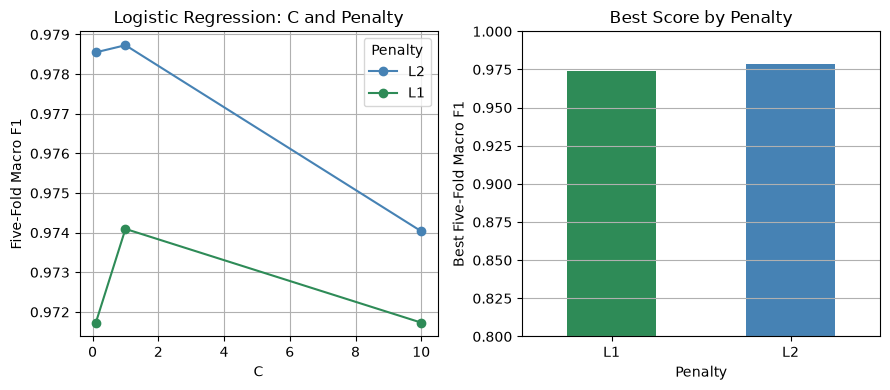

In [12]:
# plot C and L1 versus L2 results
logistic_results = pd.DataFrame(logistic_search.cv_results_)
logistic_results["Penalty"] = logistic_results["param_model__l1_ratio"].map({0: "L2", 1: "L1"})

fig, axes = plt.subplots(1, 2, figsize=(9, 4))

for penalty_name, color in [("L2", "steelblue"), ("L1", "seagreen")]:
    penalty_results = logistic_results[
        logistic_results["Penalty"] == penalty_name
    ]
    penalty_results.groupby("param_model__C")["mean_test_score"].max().plot(
        marker="o",
        ax=axes[0],
        label=penalty_name,
        color=color
    )

axes[0].set_title("Logistic Regression: C and Penalty")
axes[0].set_xlabel("C")
axes[0].set_ylabel("Five-Fold Macro F1")
axes[0].legend(title="Penalty")
axes[0].grid()

logistic_results.groupby("Penalty")["mean_test_score"].max().plot(
    kind="bar",
    ax=axes[1],
    color=["seagreen", "steelblue"],
    title="Best Score by Penalty"
)
axes[1].set_xlabel("Penalty")
axes[1].set_ylabel("Best Five-Fold Macro F1")
axes[1].set_ylim(0.8, 1.0)
axes[1].tick_params(axis="x", rotation=0)
axes[1].grid(axis="y")

plt.tight_layout()
plt.show()

### Logistic Regression Final Results

The tuned Logistic Regression model achieved a test macro F1-score of 0.981 and malignant recall of 0.976. It correctly identified 41 of 42 malignant cases and 71 of 72 benign cases. It made two total errors, including one malignant case incorrectly classified as benign.

The training and testing scores were very close, suggesting that the model generalized well and showed little evidence of substantial overfitting. Its cross-validation macro F1-score of 0.979 was also close to its test score of 0.981.

Logistic Regression test results:
              precision    recall  f1-score   support

   malignant       0.98      0.98      0.98        42
      benign       0.99      0.99      0.99        72

    accuracy                           0.98       114
   macro avg       0.98      0.98      0.98       114
weighted avg       0.98      0.98      0.98       114



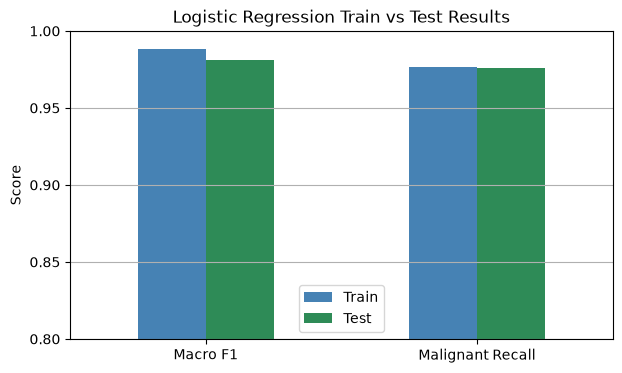

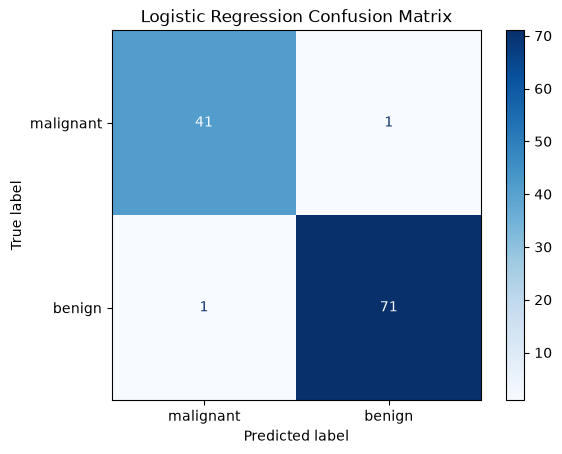

In [13]:
# use the best logistic regression model
logistic_model = logistic_search.best_estimator_

# make predictions
logistic_train_predictions = logistic_model.predict(X_train)
logistic_test_predictions = logistic_model.predict(X_test)

# calculate train and test metrics
logistic_train_scores = {
    "Macro F1": f1_score(y_train, logistic_train_predictions, average="macro"),
    "Malignant Recall": recall_score(
        y_train,
        logistic_train_predictions,
        pos_label=0
    )
}

logistic_test_scores = {
    "Macro F1": f1_score(y_test, logistic_test_predictions, average="macro"),
    "Malignant Recall": recall_score(
        y_test,
        logistic_test_predictions,
        pos_label=0
    )
}

print("Logistic Regression test results:")
print(classification_report(
    y_test,
    logistic_test_predictions,
    target_names=["malignant", "benign"]
))

# show the train and test metrics
logistic_scores = pd.DataFrame({
    "Train": logistic_train_scores,
    "Test": logistic_test_scores
})

logistic_scores.plot(
    kind="bar",
    figsize=(7, 4),
    color=["steelblue", "seagreen"],
    title="Logistic Regression Train vs Test Results"
)
plt.ylabel("Score")
plt.ylim(0.8, 1.0)
plt.yticks([0.8, 0.85, 0.9, 0.95, 1.0])
plt.xticks(rotation=0)
plt.grid(axis="y")
plt.show()

# show the confusion matrix
ConfusionMatrixDisplay.from_predictions(
    y_test,
    logistic_test_predictions,
    display_labels=["malignant", "benign"],
    cmap="Blues"
)
plt.title("Logistic Regression Confusion Matrix")
plt.show()

## Model 2: Random Forest

Random Forest is used as the second model because it can capture nonlinear
relationships and interactions between features.

The tuned parameters are:

- Number of trees
- Maximum tree depth
- Minimum samples required to split a node
- Class weight

In [14]:
# build the random forest pipeline
forest_pipeline = Pipeline([
    ("preprocessor", preprocessor),
    ("model", RandomForestClassifier(
        random_state=42,
        n_jobs=-1
    ))
])

# set the parameters to tune
forest_parameters = {
    "model__n_estimators": [100, 200],
    "model__max_depth": [None, 5, 10],
    "model__min_samples_split": [2, 5],
    "model__class_weight": [None, "balanced"]
}

# use five-fold cross-validation on the training data
forest_search = GridSearchCV(
    forest_pipeline,
    forest_parameters,
    cv=5,
    scoring="f1_macro",
    n_jobs=-1
)

forest_search.fit(X_train, y_train)

print("Random Forest validation complete")
print("cross-validation folds:", forest_search.cv)
print("parameter combinations tested:",
      len(forest_search.cv_results_["params"]))
print("Best Random Forest parameters:")
print(forest_search.best_params_)
print("Best cross-validation F1:",
      round(forest_search.best_score_, 3))

Random Forest validation complete
cross-validation folds: 5
parameter combinations tested: 24
Best Random Forest parameters:
{'model__class_weight': 'balanced', 'model__max_depth': None, 'model__min_samples_split': 2, 'model__n_estimators': 100}
Best cross-validation F1: 0.965


In [15]:
# show the random forest grid search results
forest_grid_results = pd.DataFrame(forest_search.cv_results_)

print("preprocessing step:")
print(forest_search.best_estimator_.named_steps["preprocessor"])

print("\nrandom forest grid search results:")
display(forest_grid_results[
    [
        "param_model__n_estimators",
        "param_model__max_depth",
        "param_model__min_samples_split",
        "param_model__class_weight",
        "mean_test_score",
        "std_test_score",
        "rank_test_score"
    ]
].sort_values("rank_test_score").round(3))

preprocessing step:
ColumnTransformer(transformers=[('numeric',
                                 Pipeline(steps=[('imputer',
                                                  SimpleImputer(strategy='median')),
                                                 ('scaler', StandardScaler())]),
                                 ['mean radius', 'mean texture',
                                  'mean perimeter', 'mean area',
                                  'mean smoothness', 'mean compactness',
                                  'mean concavity', 'mean concave points',
                                  'mean symmetry', 'mean fractal dimension',
                                  'radius error', 'texture error',
                                  'perimeter error', 'area error',
                                  'smoothness error', 'compactness error',
                                  'concavity error', 'concave points error',
                                  'symmetry error', 'fractal dimensi

,param_model__n_estimators,param_model__max_depth,param_model__min_samples_split,param_model__class_weight,mean_test_score,std_test_score,rank_test_score
20,100,10,2,balanced,0.965,0.013,1
12,100,None,2,balanced,0.965,0.013,1
21,200,10,2,balanced,0.960,0.012,3
13,200,None,2,balanced,0.960,0.012,3
23,200,10,5,balanced,0.958,0.016,5
15,200,None,5,balanced,0.958,0.016,5
17,200,5,2,balanced,0.958,0.012,7
14,100,None,5,balanced,0.958,0.012,7
22,100,10,5,balanced,0.958,0.012,7
16,100,5,2,balanced,0.958,0.009,10


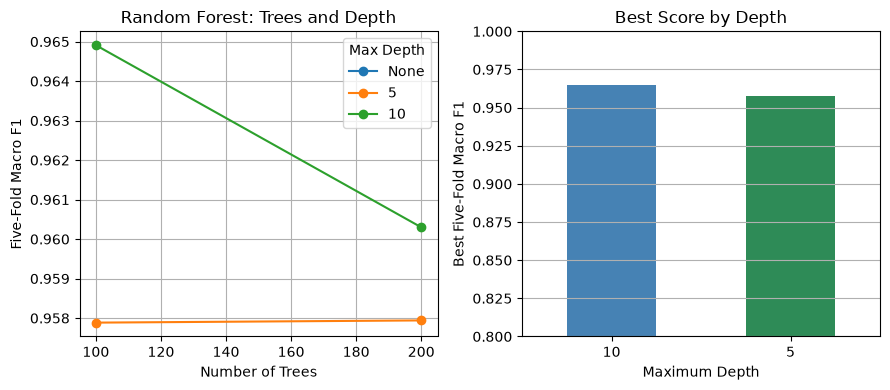

In [16]:
# plot number of trees and maximum depth
forest_results = pd.DataFrame(forest_search.cv_results_)
forest_results["Depth"] = forest_results["param_model__max_depth"].astype(str)

fig, axes = plt.subplots(1, 2, figsize=(9, 4))

for depth_name in ["None", "5", "10"]:
    depth_results = forest_results[
        forest_results["Depth"] == depth_name
    ]
    depth_results.groupby("param_model__n_estimators")["mean_test_score"].max().plot(
        marker="o",
        ax=axes[0],
        label=depth_name,
    )

axes[0].set_title("Random Forest: Trees and Depth")
axes[0].set_xlabel("Number of Trees")
axes[0].set_ylabel("Five-Fold Macro F1")
axes[0].legend(title="Max Depth")
axes[0].grid()

forest_results.groupby("Depth")["mean_test_score"].max().plot(
    kind="bar",
    ax=axes[1],
    color=["steelblue", "seagreen", "firebrick"],
    title="Best Score by Depth"
)
axes[1].set_xlabel("Maximum Depth")
axes[1].set_ylabel("Best Five-Fold Macro F1")
axes[1].set_ylim(0.8, 1.0)
axes[1].tick_params(axis="x", rotation=0)
axes[1].grid(axis="y")

plt.tight_layout()
plt.show()

### Random Forest Final Results

The tuned Random Forest model achieved a test macro F1-score of 0.944 and malignant recall of 0.952. It correctly identified 40 of 42 malignant cases and 68 of 72 benign cases. It made six total errors, including two malignant cases incorrectly classified as benign.

The model achieved perfect training scores but lower testing scores. This difference indicates some overfitting because the model learned the training data extremely well but did not generalize as effectively to unseen data.

Random Forest test results:
              precision    recall  f1-score   support

   malignant       0.91      0.95      0.93        42
      benign       0.97      0.94      0.96        72

    accuracy                           0.95       114
   macro avg       0.94      0.95      0.94       114
weighted avg       0.95      0.95      0.95       114



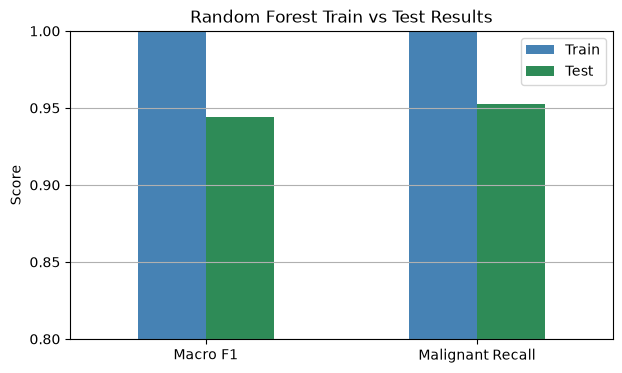

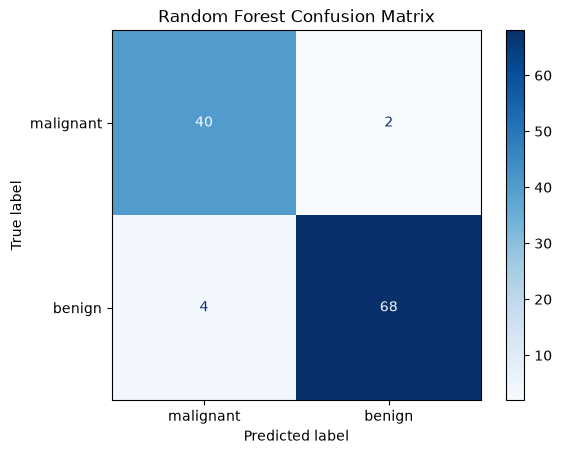

In [17]:
# use the best random forest model
forest_model = forest_search.best_estimator_

# make predictions
forest_train_predictions = forest_model.predict(X_train)
forest_test_predictions = forest_model.predict(X_test)

# calculate train and test metrics
forest_train_scores = {
    "Macro F1": f1_score(y_train, forest_train_predictions, average="macro"),
    "Malignant Recall": recall_score(
        y_train,
        forest_train_predictions,
        pos_label=0
    )
}

forest_test_scores = {
    "Macro F1": f1_score(y_test, forest_test_predictions, average="macro"),
    "Malignant Recall": recall_score(
        y_test,
        forest_test_predictions,
        pos_label=0
    )
}

print("Random Forest test results:")
print(classification_report(
    y_test,
    forest_test_predictions,
    target_names=["malignant", "benign"]
))

# show the train and test metrics
forest_scores = pd.DataFrame({
    "Train": forest_train_scores,
    "Test": forest_test_scores
})

forest_scores.plot(
    kind="bar",
    figsize=(7, 4),
    color=["steelblue", "seagreen"],
    title="Random Forest Train vs Test Results"
)
plt.ylabel("Score")
plt.ylim(0.8, 1.0)
plt.yticks([0.8, 0.85, 0.9, 0.95, 1.0])
plt.xticks(rotation=0)
plt.grid(axis="y")
plt.show()

# show the confusion matrix
ConfusionMatrixDisplay.from_predictions(
    y_test,
    forest_test_predictions,
    display_labels=["malignant", "benign"],
    cmap="Blues"
)
plt.title("Random Forest Confusion Matrix")
plt.show()

## Model Comparison

The two tuned models are compared using the same untouched test set.

The comparison focuses on:

- Macro F1-score
- Malignant recall

Malignant recall is especially important because false negatives represent
malignant cases incorrectly classified as benign.

In [18]:
# calculate final test-set metrics
comparison = pd.DataFrame({
    "Model": [
        "Logistic Regression",
        "Random Forest"
    ],
    "Macro F1": [
        f1_score(
            y_test,
            logistic_test_predictions,
            average="macro"
        ),
        f1_score(
            y_test,
            forest_test_predictions,
            average="macro"
        )
    ],
    "Malignant Recall": [
        recall_score(
            y_test,
            logistic_test_predictions,
            pos_label=0
        ),
        recall_score(
            y_test,
            forest_test_predictions,
            pos_label=0
        )
    ]
})

display(comparison.round(3))

,Model,Macro F1,Malignant Recall
0,Logistic Regression,0.981,0.976
1,Random Forest,0.944,0.952


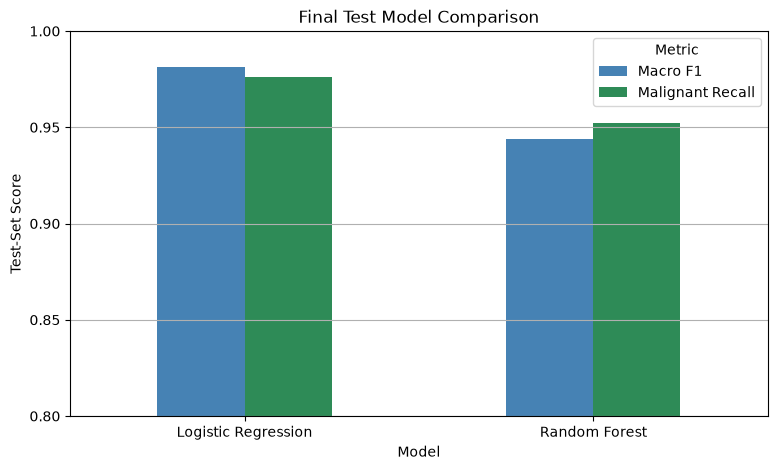

In [19]:
# compare the two final test metrics
comparison_plot = comparison.set_index("Model")[
    ["Macro F1", "Malignant Recall"]
]

comparison_plot.plot(
    kind="bar",
    figsize=(9, 5),
    color=["steelblue", "seagreen"],
    ylim=(0.8, 1.0),
    title="Final Test Model Comparison"
)

plt.ylabel("Test-Set Score")
plt.yticks([0.8, 0.85, 0.9, 0.95, 1.0])
plt.xticks(rotation=0)
plt.legend(title="Metric")
plt.grid(axis="y")
plt.show()

## Conclusion and Future Work

### Findings

- Logistic Regression achieved a test macro F1-score of 0.981 and malignant recall of 0.976.
- Random Forest achieved a test macro F1-score of 0.944 and malignant recall of 0.952.
- Logistic Regression made two incorrect predictions and missed one malignant case.
- Random Forest made six incorrect predictions and missed two malignant cases.
- Logistic Regression is the preferred model because it performed better on both selected metrics and showed a smaller difference between its training and testing results.

### Limitations

- The dataset contains only 569 samples, so the results may change with a larger dataset.
- The data comes from one public dataset and may not represent every patient population or clinical setting.
- The predictors describe cell-nucleus measurements but do not include other clinical information, such as patient history or genetic factors.
- The final results are based on one test split containing 114 samples.
- Strong performance on this dataset does not mean that the model is ready for clinical use.

### Future Work

- Evaluate Logistic Regression on an independent external dataset.
- Use repeated cross-validation to examine the stability of the results.
- Tune the classification threshold to potentially improve malignant recall.
- Compare additional models such as support vector machines and gradient boosting.
- Examine model coefficients or other explanation methods to determine which measurements contribute most strongly to the predictions.